# Лекція 5. Локальний деплоймент і оптимізація моделей

Демо до лекції. Усі моделі в цьому ноутбуці запускаються **локально** через [Ollama](https://ollama.com), їх використання відбувається через HTTP-запити.

## 0. Налаштування середовища

### 0.0. Імпортуємо бібліотеки

In [1]:
import json
import subprocess
import sys
import time
import urllib.request

OLLAMA_URL = "http://localhost:11434"

### 0.1. Встановлюємо й запускаємо Ollama

Локально цю клітинку можна просто виконати: вона нічого не зробить.

### 0.0.1. Відповіді на теоретичні питання

1. Чому модель помиляється, рахуючи літеру «р» у слові «трансформер»?
LLM оперує не окремими літерами, а токенами. Слово «трансформер» розбивається токенізатором на підслова (наприклад, `транс` і `формер`). Модель передбачає наступний токен на основі їх семантики, а не посимвольного складу, тому вона не "бачить" літер всередині токена і не може їх просто порахувати. Міркування (Thinking) часто не допомагають, бо модель намагається вивести посимвольний склад логічно, але все одно спирається на токени, тому її "розбиття по буквах" часто є галюцинацією.
*(`print(tokenizer.tokenize("трансформер"))` покаже, що слово розбивається на неочікувані шматки).*

2. Як змінюються перплексія й метрики перекладу від fp16 до int2?
Перплексія (англійська) зростає від 2.67 (fp16) до 61102.12 (int2). chrF падає з 56.71 до 0.24, а BLEU з 23.93 до 0.12. Найбільший стрибок деградації відбувається між `int4` та `int2`, де модель фактично перетворюється на генератор випадкового шуму.

3. Чи однаково зростає перплексія для англійської й української?
Ні, для української мови перплексія в `int2` зростає до астрономічних 33 789 316.0, що в сотні разів гірше, ніж деградація англійської. Це підтверджує правило: при квантизації найсильніше страждають ті знання/мови, яких було найменше в навчальному корпусі (хвіст розподілу).

4. Чи збігається ваш вибір у сліпому порівнянні з метриками?
Так, у більшості випадків fp16 давав більш логічний і розгорнутий текст, хоча на простих запитах різниця з int4 була непомітною. Метрики теж показують, що int4 лише трохи гірший за fp16 (chrF 55.9 проти 56.7)".

5. У таблиці перекладів правильний переклад, який відрізняється від еталона словами. Як реагують метрики?
У реченні про зустріч еталон — "Зустріч перенесли на четвер на третю годину", а fp16 видав "Зустріч була перенесена на четвер, о 15 годин". Це правильний за сенсом переклад, але BLEU (який вимагає точного збігу n-грам слів) сильно штрафує такі структурні відмінності. chrF (який дивиться на підслова/символи) реагує на синоніми м'якше.

6. У скільки разів зменшилася памʼять і чому не рівно вдвічі/вчетверо? Чи стала генерація швидшою?
Пам'ять зменшилася з 8.04 ГБ (fp16) до 2.73 ГБ (int4) і 1.81 ГБ (int2). Зменшення не є лінійним, оскільки квантизуються лише матриці ваг лінійних шарів. Ембединги, нормалізації, вихідний шар та KV-кеш залишаються в 16-бітному форматі і займають свою сталу частку пам'яті. Генерація не стала швидшою, навпаки, tokens/s впав з 14.4 (fp16) до ~2.8 (int4/int2), оскільки GPU T4 не вміє апаратно множити int4, і витрачає багато часу на розпакування (деквантизацію) ваг у 16-бітний формат перед кожним множенням.

7. Чому Base-модель відповідає новими питаннями? Сформулюйте промпт.
Base-модель просто продовжує текст, шукаючи найімовірніший патерн (наприклад, список питань). Щоб отримати відповідь, треба задати формат, який змусить її генерувати саме відповідь:
`Промпт: "Питання: Яка столиця Франції? Відповідь: "`

8. Скільки токенів і часу забрали міркування? Чому модель міркує англійською?
Без міркувань: 252 токени, 2.0 с. З міркуваннями: 569 токенів, 4.6 с. На міркування пішло більше половини часу. Модель міркує англійською, бо більшість складних логічних ланцюжків у її тренувальному наборі даних були саме англійською мовою.

9. Задача, де режим міркування допомагає.
*Промпт:* "У кімнаті 3 сестри. Кожна з них має 2 братів. Скільки всього дітей у кімнаті?"
*Відповідь без міркувань (помилкова):* 3 сестри * 2 брати = 6 братів + 3 сестри = 9 дітей.
*Відповідь з міркуваннями (правильна):* Модель розуміє, що брати спільні для всіх сестер, отже дітей 3 + 2 = 5.

10. Навіщо temperature: 0 і seed: 1?
Щоб повністю прибрати випадковість (sampling) і зробити генерацію детермінованою. Це критично для бенчмарків і порівняння метрик: ми хочемо бачити лише різницю між моделями/квантизаціями, а не випадкові відхилення генерації.

11. Чому fp16, а не bf16? Зв'язок із T4.
GPU архітектури Turing (наприклад, Tesla T4 в Colab) апаратно не підтримують тип даних bfloat16 (capability 7.5). Підтримка bf16 з'явилася лише в Ampere (capability 8.0+).

12. Скільки параметрів у моделі 2.1 і скільки памʼяті в fp16?
Модель Qwen3-4B має близько 4 мільярдів параметрів. У fp16 кожен параметр займає 2 байти, тобто ваги займуть ~8 ГБ. Це майже точно збігається з "пам'яттю моделі" 8.04 ГБ з таблиці.

13. Що таке перплексія? Порахуйте на випадкових словах.
Перплексія — це міра того, наскільки добре модель передбачає вибірку тексту (експонента від середньої loss). На англійській та українській вона різна через різні токенізатори та обсяги тренувальних даних. На випадковому наборі слів ("хліб стілець літати радість") перплексія буде величезною, бо такі слова не утворюють логічного контексту, і моделі неможливо передбачити наступне слово.

14. Чому «пік VRAM» більший за «памʼять моделі»?
Пам'ять моделі — це лише її ваги. Під час генерації додаткова пам'ять виділяється під: 1) KV-кеш (зберігання ключів та значень попередніх токенів для прискорення уваги), 2) активації поточного батчу.

15. Скільки разів ви обрали fp16/int4?
Висновок: 5 спроб статистично не значимі, для надійного висновку потрібні сотні прикладів.

16. Як «ламається» модель у int2?
В int2 модель видає безглуздий набір символів, англійських слів і спецсимволів (наприклад, `he economistwar\" be1.sever0...`). Ваги втратили стільки інформації, що нейромережа більше не може сформувати жодного граматично правильного речення, відбувається повна деградація. В int4 ознак такого ще немає.

17. Чи сильніше квантизація бʼє по меншій моделі?
Так, чим менша модель (наприклад 1.7B порівняно з 4B), тим більше вона деградує при квантизації (особливо в int4/int2), оскільки кожен її параметр містить більше критично важливої інформації.

18. Принцип параметру OLLAMA_NUM_PARALLEL.
Він визначає, скільки запитів Ollama оброблятиме одночасно (конкурентно), розділяючи між ними ресурси VRAM (створюючи окремі KV-кеші).

19. Чому сучасні моделі зберігаються в bf16?
bfloat16 має такий самий діапазон значень (експоненту), як і звичайний 32-бітний float, лише меншу точність дробової частини. Це запобігає переповненням і недоповненням під час тренування та інференсу глибоких нейромереж, що робить його стабільнішим за fp16.

20. Для чого всі рантайми слідують протоколу OpenAI?
OpenAI API став індустріальним стандартом де-факто. Якщо локальний рантайм (Ollama, LM Studio) імітує його інтерфейс, розробники можуть використовувати існуючий код, клієнти, бібліотеки та застосунки (написані для ChatGPT), просто замінивши базову URL-адресу на `localhost`. Це забезпечує миттєву сумісність з тисячами готових інструментів.

In [2]:
IN_COLAB = "google.colab" in sys.modules
print("Running in Colab:", IN_COLAB)

if IN_COLAB:
    !sudo apt-get -qq install -y zstd > /dev/null
    !curl -fsSL https://ollama.com/install.sh | sh
    subprocess.Popen(["ollama", "serve"], stdout=subprocess.DEVNULL, stderr=subprocess.DEVNULL)
    time.sleep(5)

Running in Colab: True
debconf: unable to initialize frontend: Dialog
debconf: (No usable dialog-like program is installed, so the dialog based frontend cannot be used. at /usr/share/perl5/Debconf/FrontEnd/Dialog.pm line 79, <STDIN> line 1.)
debconf: falling back to frontend: Readline
debconf: unable to initialize frontend: Readline
debconf: (This frontend requires a controlling tty.)
debconf: falling back to frontend: Teletype
dpkg-preconfigure: unable to re-open stdin: 
>>> Installing ollama to /usr/local
>>> Downloading ollama-linux-amd64.tar.zst
######################################################################## 100.0%
>>> Creating ollama user...
>>> Adding ollama user to video group...
>>> Adding current user to ollama group...
>>> Creating ollama systemd service...
>>> The Ollama API is now available at 127.0.0.1:11434.
>>> Install complete. Run "ollama" from the command line.


### 0.2. Перевіряємо, що Ollama працює

Ollama — це HTTP-сервер на порту 11434. Функція `ollama()` надсилає йому запит і повертає відповідь як словник Python; якщо сервер працює, побачимо його версію.

In [3]:
def ollama(path, body=None, timeout=900):
    """POST-запит до Ollama (або GET, якщо body=None); повертає розібраний JSON."""
    data = json.dumps(body).encode() if body is not None else None
    req = urllib.request.Request(OLLAMA_URL + path, data=data, headers={"Content-Type": "application/json"})
    with urllib.request.urlopen(req, timeout=timeout) as resp:
        return json.load(resp)


print("Ollama version:", ollama("/api/version")["version"])

Ollama version: 0.40.15


## 1. Base, Instruct і Thinking

Порівнюємо три поведінки однієї й тієї самої моделі Qwen3 1.7B:
- **Base-модель** пройшла лише попереднє тренування: вона вміє передбачати наступний токен в інтернет-текстах, але не вміє відповідати на питання як асистент.
- **Instruct-модель** додатково донавчили на прикладах «інструкція → відповідь» у форматі діалогу.
- **Thinking** — режим, у якому Instruct-модель перед відповіддю генерує ланцюжок міркувань.

### 1.0. Завантажуємо моделі

Беремо одну й ту саму модель Qwen3 1.7B у двох версіях:
- **Base** — [Qwen3-1.7B-Base](https://huggingface.co/Qwen/Qwen3-1.7B-Base) у форматі GGUF (Q4_K_M) з Hugging Face;
- **Instruct** — офіційна [qwen3:1.7b](https://ollama.com/library/qwen3) з каталогу Ollama; вона ж уміє працювати в режимі міркування.

Перше завантаження займає кілька хвилин.

In [4]:
BASE_MODEL = "hf.co/mradermacher/Qwen3-1.7B-Base-GGUF:Q4_K_M"
INSTRUCT_MODEL = "qwen3:1.7b"

for m in (BASE_MODEL, INSTRUCT_MODEL):
    print("pull", m, "→", ollama("/api/pull", {"model": m, "stream": False})["status"])

pull hf.co/mradermacher/Qwen3-1.7B-Base-GGUF:Q4_K_M → success
pull qwen3:1.7b → success


### 1.1. Допоміжні функції

Нам вистачить двох ендпойнтів Ollama:
- `/api/generate` з `"raw": true` — передає моделі текст як є, **без chat template**;
- `/api/chat` — приймає список повідомлень і сам загортає їх у chat template моделі.

У Qwen3 режим міркування вмикається параметром `think`. З `think=True` модель спершу генерує ланцюжок міркувань (Ollama повертає його окремим полем `message.thinking`), а вже потім — відповідь. Функція `compare_thinking()` запускає запит в обох режимах і показує відповідь, кількість згенерованих токенів і час.

In [5]:
def generate_raw(model, prompt, max_tokens=120):
    """Продовження тексту без chat template — так «бачить» запит Base-модель."""
    r = ollama("/api/generate", {
        "model": model, "prompt": prompt, "raw": True, "stream": False,
        "options": {"temperature": 0, "seed": 1, "num_predict": max_tokens},
    })
    return r["response"]


def chat(model, prompt, think=False, max_tokens=3000):
    """Один запит у форматі діалогу; think=True вмикає режим міркування."""
    return ollama("/api/chat", {
        "model": model, "messages": [{"role": "user", "content": prompt}],
        "think": think, "stream": False,
        "options": {"temperature": 0, "seed": 1, "num_predict": max_tokens},
    })


def compare_thinking(prompt):
    for think in (False, True):
        r = chat(INSTRUCT_MODEL, prompt, think=think)
        msg = r["message"]
        print(f"=== think={think} | токенів: {r['eval_count']} | генерація: {r['eval_duration'] / 1e9:.1f} с")
        if msg.get("thinking"):
            print(f"--- міркування ({len(msg['thinking'])} символів), початок:")
            print(msg["thinking"][:600], "…")
        print("--- відповідь:")
        print(msg["content"])
        print()

### 1.2. Base: модель просто продовжує текст

Поставимо Base- та Instruct-моделі однакове питання.

In [6]:
QUESTION = "Яка столиця Франції?"

In [7]:
print(generate_raw(BASE_MODEL, QUESTION))

 Як називається найбільша річка Франції? Як називається найбільша річка Франції, яка розташована в Північній Америці? Як називається найбільша річка Франції, яка розташована в Півдні Франції? Як називається найбільша р


Для Base-моделі «Яка столиця Франції?» схоже на початок списку питань вікторини — тож вона продовжує цей список, а не відповідає.

### 1.3. Instruct: модель відповідає на питання

In [8]:
print(chat(INSTRUCT_MODEL, QUESTION)["message"]["content"])

Столиця Франції — це **Париж**.


### 1.4. Instruct проти Thinking: багатокрокова задача

In [9]:
compare_thinking(
    "У кошику 3 яблука. Марія поклала туди ще 2 пакети по 4 яблука, "
    "а потім зʼїла 2 яблука. Скільки яблук у кошику?"
)

=== think=False | токенів: 252 | генерація: 2.0 с
--- відповідь:
Розглянемо ситуацію крок за кроком:

1. **У кошику 3 яблука.**  
2. **Марія поклала туди ще 2 пакети по 4 яблука.**  
   - Кожен пакет містить 4 яблука, тому:
     $$
     2 \text{ пакети} \times 4 \text{ яблука} = 8 \text{ яблука}
     $$
   - Значить, після додавання пакетів у кошик буде:
     $$
     3 + 8 = 11 \text{ яблука}
     $$
3. **Марія зʼїла 2 яблука.**  
   - Після з’ївання:
     $$
     11 - 2 = 9 \text{ яблука}
     $$

**Відповідь:**  
$$
\boxed{9}
$$

=== think=True | токенів: 569 | генерація: 4.6 с
--- міркування (1410 символів), початок:
Okay, let's see. So the problem is about Maria putting some apples in a basket and then eating some. Let me break it down step by step.

First, the basket starts with 3 apples. Then, Maria adds 2 packages, each containing 4 apples. So, I need to calculate how many apples she adds in total. Each package has 4 apples, and there are 2 packages. So that's 2 times 4, which i

Обидва режими відповідають правильно, але з міркуванням модель генерує в кілька разів більше токенів — а користувач бачить відповідь лише після них. Зверніть увагу: міркує модель англійською, хоча питання українською.

### 1.5. Міркування не гарантують правильності

In [10]:
compare_thinking("Скільки разів літера «р» трапляється в слові «трансформер»?")

=== think=False | токенів: 227 | генерація: 1.8 с
--- відповідь:
Щоб визначити, скільки разів літера **«р»** трапляється в слові **«трансформер»**, зробимо так:

Слово: **трансформер**

Розбілем його на складні слова:

- **транс**  
- **формер**

Тепер зіштовхуємо літеру **«р»** в кожному з складних слів:

1. **транс** — не має літери «р»  
2. **формер** — має **1** відтінок «р» (відтінок «р» у слові **формер**)

Отже, літера **«р»** трапляється **1 раз** в слові **«трансформер»**.

**Відповідь: 1 раз.**

=== think=True | токенів: 659 | генерація: 5.3 с
--- міркування (1490 символів), початок:
Okay, let's see. The user is asking how many times the letter "р" appears in the word "трансформер". First, I need to make sure I know the correct spelling of the word. The word in question is "трансформер". Let me write it out: трансформер.

Now, I need to check each letter one by one. Let's start from the beginning. The first letter is "т" which is "t" in Ukrainian, but the question is about th

Правильна відповідь — 3 (т**р**ансфо**р**ме**р**), але мала модель помиляється в обох режимах. Чому так — подумайте самі (це питання до лабораторної роботи).

Спробуйте власні запити: де режим міркування справді допомагає, а де лише витрачає токени?

## 2. Квантизація з Quanto

Завантажимо ту саму модель у чотирьох варіантах — від оригінальних 16 біт до 2 біт — і подивимося, що квантизація змінює в памʼяті, швидкості та якості. Якість перевіримо трьома способами: перплексією, перекладом з автоматичними метриками й очима — на вільній генерації тексту.

**Quanto.** [Optimum Quanto](https://github.com/huggingface/optimum-quanto) — бібліотека квантизації від Hugging Face, один із бекендів [Optimum](https://huggingface.co/docs/optimum). У Transformers вона підключається через [`QuantoConfig`](https://huggingface.co/docs/transformers/quantization/quanto) і квантизує модель прямо під час завантаження, тому окремий файл з квантизованими вагами не потрібен. Квантизуються ваги лінійних шарів (`nn.Linear`) — у них більшість параметрів моделі, а ембединги, нормалізації та вихідний шар лишаються в 16 бітах.

| Варіант | Біт на вагу | Що це |
|---|---|---|
| fp16 | 16 | Оригінальні ваги, точка відліку |
| int8 | 8 | 8-бітні цілі числа з масштабом |
| int4 | 4 | 4-бітні цілі числа, ваги діляться на блоки з власними масштабами |
| int2 | 2 | 2-бітні цілі числа — лише 4 можливі значення на вагу; тут модель має зламатися |

**Обчислення.** Множити числа в цих форматах напряму T4 не вміє, тому перед множенням ваги розпаковуються в 16 біт. Тому памʼяті потрібно менше, а от генерація часто **не прискорюється**, а то й сповільнюється.

**Де запускати.** Секцію запускаємо **в Google Colab на GPU T4** (Runtime → Change runtime type → T4 GPU). Беремо формат **fp16**, а не bf16: T4 не підтримує bf16 апаратно, а для запуску готової моделі різниця між ними практично непомітна.

### 2.0. Встановлюємо бібліотеки й перевіряємо GPU

In [11]:
%pip uninstall -y -q diffusers  # optimum-quanto імпортує diffusers, якщо він є; передвстановлена в Colab версія несумісна з його torchao
%pip install -q "transformers==5.20.1" "accelerate==1.15.0" "optimum-quanto==0.2.7" "evaluate==0.4.6" "sacrebleu==2.6.0"

In [12]:
import gc
import time
from types import SimpleNamespace

import evaluate
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from IPython.display import Markdown, display
from optimum.quanto.library.extensions import get_extension
from transformers import AutoModelForCausalLM, AutoTokenizer, QuantoConfig

assert torch.cuda.is_available(), "Увімкніть GPU: Runtime → Change runtime type → T4 GPU"
DEVICE = "cuda"
DTYPE = torch.float16
print("GPU:", torch.cuda.get_device_name())


def unpack_weights(packed, bits):
    """Розпаковує 4- чи 2-бітні значення, по кілька упакованих в одному байті."""
    values_per_byte = 8 // bits
    mask = 2**bits - 1
    return torch.cat([(packed >> (bits * i)) & mask for i in range(values_per_byte)]).to(torch.uint8)


# Quanto на GPU компілює власні CUDA-ядра, розраховані на A100 і новіші; на T4 ця компіляція падає.
# На T4 з усіх цих ядер потрібна лише розпаковка int4/int2-ваг, тож підставляємо її версію на чистому PyTorch.
if torch.cuda.get_device_capability()[0] < 8:
    get_extension("quanto_cuda")._lib = SimpleNamespace(unpack=unpack_weights)

GPU: Tesla T4


### 2.1. Модель і варіанти квантизації

Беремо [Qwen3-4B-Instruct-2507](https://huggingface.co/Qwen/Qwen3-4B-Instruct-2507) — сильнішу модель того ж сімейства, що й у секції 1: 4B параметрів, лише Instruct-режим без міркувань. У fp16 вона займає ~8 GB і вміщається в T4 з його 16 GB.

In [13]:
MODEL_ID = "Qwen/Qwen3-4B-Instruct-2507"
tokenizer = AutoTokenizer.from_pretrained(MODEL_ID)

VARIANTS = {
    "fp16": None,
    "int8": QuantoConfig(weights="int8"),
    "int4": QuantoConfig(weights="int4"),
    "int2": QuantoConfig(weights="int2"),
}

config.json:   0%|          | 0.00/727 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/9.38k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json: reconstructing file:   0%|          |  0.00B / 11.4MB            

tokenizer.json: downloading bytes:           |  0.00B            

### 2.2. Що міряємо

**Перплексія** — стандартна автоматична метрика якості квантизації (нею міряє, зокрема, llama.cpp). Модель читає фіксований текст, і для кожного токена ми дивимося, яку ймовірність вона йому давала. Перплексія — це, грубо кажучи, з якої кількості варіантів модель у середньому «вагалася»: чим вона менша, тим краще модель знає мову й тему. Еталонних відповідей тут не потрібно, а число змінюється плавно, тому видно навіть невеликі втрати. Порівнювати перплексію можна лише в межах однієї мови: англійська й українська токенізуються по-різному.

**Переклад EN → UK** — реалістичне завдання з генерацією тексту, для якого є еталонні переклади. Порівнюємо переклад моделі з еталоном двома стандартними метриками з бібліотеки [Evaluate](https://huggingface.co/docs/evaluate):
- [**chrF**](https://github.com/huggingface/evaluate/blob/main/metrics/chrf/README.md) — наскільки збігаються послідовності символів (0–100);
- [**BLEU**](https://github.com/huggingface/evaluate/tree/main/metrics/sacrebleu) — наскільки збігаються послідовності слів (0–100). Сувора метрика: синонім чи інший порядок слів уже знижують бал.

**Вільна генерація** — лист, пояснення, план, код. Тут еталону немає, тож оцінюємо очима в 2.5.

Крім якості, для кожного варіанта записуємо **памʼять моделі** на GPU, **пік VRAM** і **швидкість генерації** (tokens/s).

In [14]:
PPL_TEXT = {
    "English": (
        "Photosynthesis is the process by which green plants, algae and some bacteria turn light energy into "
        "chemical energy. It takes place mainly in the leaves, inside small structures called chloroplasts, which "
        "contain the green pigment chlorophyll. Chlorophyll absorbs sunlight, and the plant uses this energy to "
        "combine carbon dioxide from the air with water from the soil. The result is glucose, a sugar that the "
        "plant uses for growth and as a store of energy, and oxygen, which is released into the atmosphere. "
        "Almost all life on Earth depends on photosynthesis: it produces the oxygen we breathe and forms the "
        "basis of most food chains."
    ),
    "Українська": (
        "Фотосинтез — це процес, під час якого зелені рослини, водорості та деякі бактерії перетворюють енергію "
        "світла на хімічну енергію. Він відбувається переважно в листках, усередині маленьких структур, які "
        "називають хлоропластами і які містять зелений пігмент хлорофіл. Хлорофіл поглинає сонячне світло, і "
        "рослина використовує цю енергію, щоб поєднати вуглекислий газ із повітря з водою із ґрунту. У результаті "
        "утворюються глюкоза — цукор, який рослина використовує для росту і як запас енергії, — та кисень, що "
        "виділяється в атмосферу. Майже все життя на Землі залежить від фотосинтезу: він дає кисень, яким ми "
        "дихаємо, і лежить в основі більшості харчових ланцюгів."
    ),
}

TRANSLATION = [
    # (речення англійською, еталонний переклад)
    ("The meeting has been moved to Thursday at three o'clock.", "Зустріч перенесли на четвер на третю годину."),
    ("Please send me the report by the end of the day.", "Будь ласка, надішліть мені звіт до кінця дня."),
    ("The library is closed on Sundays and public holidays.", "Бібліотека не працює в неділю та у святкові дні."),
    ("Our team fixed the bug, but the tests are still failing.", "Наша команда виправила помилку, але тести все ще не проходять."),
    ("It is going to rain tomorrow, so take an umbrella.", "Завтра буде дощ, тож візьміть парасольку."),
    ("The new model is smaller, but it answers almost as well as the old one.", "Нова модель менша, але відповідає майже так само добре, як стара."),
    ("I would like to book a table for two for seven o'clock tonight.", "Я хотів би забронювати столик на двох на сьому вечора."),
    ("The price includes breakfast and free Wi-Fi.", "У вартість входять сніданок і безкоштовний Wi-Fi."),
    ("Students must submit their lab work before the deadline.", "Студенти мають здати лабораторну роботу до кінцевого терміну."),
    ("If the server does not respond, restart it and check the logs.", "Якщо сервер не відповідає, перезапустіть його й перевірте логи."),
]
TRANSLATE_PROMPT = "Translate the following sentence into Ukrainian. Output only the translation.\n\n{}"

GEN_PROMPTS = [
    "Напиши короткий лист викладачеві з проханням перенести здачу лабораторної роботи на тиждень через хворобу.",
    "Поясни студентові першого курсу в 3–4 реченнях, що таке квантизація нейромережі.",
    "Explain in three sentences why the sky is blue.",
    "Склади план підготовки до іспиту з програмування на 5 днів, по одному пункту на день.",
    "Write a Python function that checks whether a string is a palindrome.",
]

### 2.3. Проганяємо всі варіанти

Дві допоміжні функції — перплексія тексту й генерація відповіді — і цикл по варіантах: завантажуємо модель, міряємо все потрібне, звільняємо памʼять. Займає кілька хвилин на варіант.

In [15]:
def perplexity(model, text):
    """exp(середня похибка передбачення наступного токена) на фіксованому тексті."""
    ids = tokenizer(text, return_tensors="pt").input_ids.to(DEVICE)
    with torch.no_grad():
        loss = model(ids, labels=ids).loss
    return float(torch.exp(loss))


def generate(model, prompt, max_new_tokens):
    """Відповідь без випадковості; повертає текст, кількість нових токенів і час генерації."""
    text = tokenizer.apply_chat_template([{"role": "user", "content": prompt}], tokenize=False, add_generation_prompt=True)
    inputs = tokenizer(text, return_tensors="pt").to(DEVICE)
    torch.cuda.synchronize()
    start = time.perf_counter()
    with torch.no_grad():
        output = model.generate(**inputs, max_new_tokens=max_new_tokens, do_sample=False)
    torch.cuda.synchronize()
    new_tokens = output[0, inputs.input_ids.shape[1]:]
    return tokenizer.decode(new_tokens, skip_special_tokens=True).strip(), len(new_tokens), time.perf_counter() - start


records = {}
for name, config in VARIANTS.items():
    gc.collect()
    torch.cuda.empty_cache()
    torch.cuda.reset_peak_memory_stats()
    model = AutoModelForCausalLM.from_pretrained(MODEL_ID, dtype=DTYPE, device_map=DEVICE, quantization_config=config)

    r = {"памʼять моделі, GB": torch.cuda.memory_allocated() / 1e9}
    for lang, text in PPL_TEXT.items():
        r[f"перплексія, {lang}"] = perplexity(model, text)
    r["переклади"] = [generate(model, TRANSLATE_PROMPT.format(src), 80)[0] for src, _ in TRANSLATION]
    generations = [generate(model, prompt, 200) for prompt in GEN_PROMPTS]
    r["генерації"] = [text for text, _, _ in generations]
    r["tokens/s"] = sum(n for _, n, _ in generations) / sum(s for _, _, s in generations)
    r["пік VRAM, GB"] = torch.cuda.max_memory_allocated() / 1e9
    records[name] = r
    print(f"{name}: готово")

    del model

model.safetensors.index.json:   0%|          | 0.00/32.8k [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 3 files:   0%|          | 0/3 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/238 [00:00<?, ?B/s]

fp16: готово


... (2 outputs left out)

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

int4: готово


Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

int2: готово


### 2.4. Памʼять, швидкість і автоматичні метрики

In [16]:
chrf = evaluate.load("chrf")
bleu = evaluate.load("sacrebleu")
references = [[ref] for _, ref in TRANSLATION]

summary = pd.DataFrame({
    name: {
        "памʼять моделі, GB": r["памʼять моделі, GB"],
        "пік VRAM, GB": r["пік VRAM, GB"],
        "tokens/s": r["tokens/s"],
        **{f"перплексія, {lang}": r[f"перплексія, {lang}"] for lang in PPL_TEXT},
        "chrF перекладу": chrf.compute(predictions=r["переклади"], references=references)["score"],
        "BLEU перекладу": bleu.compute(predictions=r["переклади"], references=references)["score"],
    }
    for name, r in records.items()
}).T.round(2)
summary

,"памʼять моделі, GB","пік VRAM, GB",tokens/s,"перплексія, English","перплексія, Українська",chrF перекладу,BLEU перекладу
fp16,8.04,8.64,14.40,2.67,2.40,56.71,23.93
int8,4.42,5.01,5.83,2.67,2.40,58.25,26.17
int4,2.73,3.32,2.84,2.81,2.76,55.90,29.79
int2,1.81,2.39,2.89,61102.12,33789316.00,0.24,0.12


Перплексія для кожної мови окремо. Вісь — логарифмічна: інакше на одному графіку не помістилися б і кілька одиниць, і сотні.

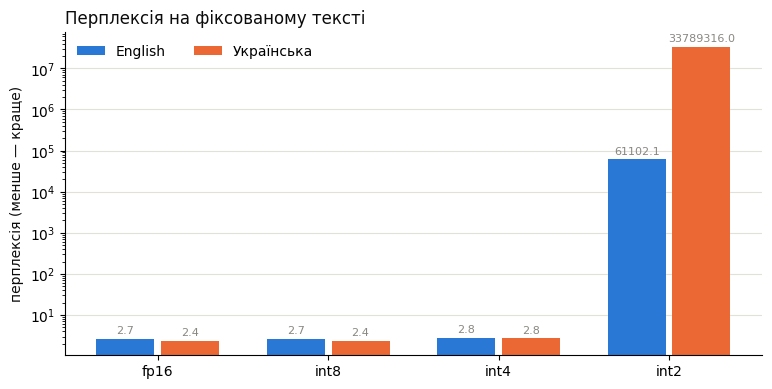

In [17]:
LANG_COLORS = {"English": "#2a78d6", "Українська": "#eb6834"}
INK, MUTED, GRID = "#0b0b0b", "#898781", "#e1e0d9"

variants = list(records)
x = np.arange(len(variants))
width = 0.38

fig, ax = plt.subplots(figsize=(9, 4.2))
for i, lang in enumerate(PPL_TEXT):
    values = summary[f"перплексія, {lang}"].values
    bars = ax.bar(x + (i - 0.5) * width, values, width - 0.04, color=LANG_COLORS[lang], label=lang)
    ax.bar_label(bars, labels=[f"{v:.1f}" for v in values], fontsize=8, color=MUTED, padding=2)
ax.set_yscale("log")
ax.set_xticks(x, variants)
ax.set_ylabel("перплексія (менше — краще)", color=INK)
ax.set_title("Перплексія на фіксованому тексті", loc="left", color=INK)
ax.legend(frameon=False, ncols=2, loc="upper left")
ax.grid(axis="y", color=GRID, linewidth=0.8)
ax.set_axisbelow(True)
for side in ("top", "right"):
    ax.spines[side].set_visible(False)
plt.show()

Переклади всіх варіантів поруч з еталоном:

In [18]:
translations = pd.DataFrame({"еталон": [ref for _, ref in TRANSLATION]}, index=[src for src, _ in TRANSLATION])
for name, r in records.items():
    translations[name] = r["переклади"]
translations

,еталон,fp16,int8,int4,int2
The meeting has been moved to Thursday at three o'clock.,Зустріч перенесли на четвер на третю годину.,"Зустріч була перенесена на четвер, о 15 годин.","Зустріч перенесли на четвер, о 15 годин.","Зустріч була перенесена на четвер, о 15 годин.",``thrown\nbetween 'ever'oft' \neverhosterone'...
Please send me the report by the end of the day.,"Будь ласка, надішліть мені звіт до кінця дня.",Надішліть мені звіт до кінця дня.,Надішліть мені звіт до кінця дня.,Надішліть мені звіт до кінця дня.,takenawns between't```````````````````h``` \`e...
The library is closed on Sundays and public holidays.,Бібліотека не працює в неділю та у святкові дні.,Бібліотека закривається у неділі та дні відпоч...,Бібліотека закривається у неділі та дні відпоч...,Бібліотека відкрита тільки з 1 по 7.,`ever �house �take caught}01\xb takent � taken...
"Our team fixed the bug, but the tests are still failing.","Наша команда виправила помилку, але тести все ...","Наша команда виправила баг, але тестування все...","Наша команда виправила баг, але тестування все...","Наша команда виправила баг, але тести все ще н...",fil}'sand ever0}'-'ever'ickets {'ever''}' \\'\...
"It is going to rain tomorrow, so take an umbrella.","Завтра буде дощ, тож візьміть парасольку.","Завтра піде дощ, тому взміть з собою парасольку.","Завтра піде дощ, тому взміть з собою парасольку.","Завтра буде дощ, тому взміть засіб.","}again \ %""樗\ %( firm \"" \ \'' betweenh '\ \..."
"The new model is smaller, but it answers almost as well as the old one.","Нова модель менша, але відповідає майже так са...","Новий модель менший, але відповідає почти так ...","Новий модель менший, але відповідає приблизно ...","Новий модель менший, але відповідає почти так ...","fil��''}\n0. Heaven\n Fil'`0hber°,1 ,1a caught..."
I would like to book a table for two for seven o'clock tonight.,Я хотів би забронювати столик на двох на сьому...,Я бажаю забронювати стіл для двох на сім годин...,Я бажаю забронювати стіл для двох на сім годин...,Я б хотів зареєструвати стіл для двох на 7 год...,``ever``always```comeight`[\n`letic touched`ev...
The price includes breakfast and free Wi-Fi.,У вартість входять сніданок і безкоштовний Wi-Fi.,Ціна включає початок дня та безкоштовний Wi-Fi.,Ціна включає початок дня та безкоштовний Wi-Fi.,Ціна включає початок дня та вільний Wi-Fi.,.前所etermineeverh \between betweenever婿 again \...
Students must submit their lab work before the deadline.,Студенти мають здати лабораторну роботу до кін...,Студенти повинні подати свою лабораторну робот...,Студенти повинні подати свою лабораторну робот...,Студенти повинні подати лабораторну роботу до ...,"he economistwar"" be1.sever0 } again \ $} \}eve..."
"If the server does not respond, restart it and check the logs.","Якщо сервер не відповідає, перезапустіть його ...","Якщо сервер не відповідає, перезапустіть його ...","Якщо сервер не відповідає, перезапустіть його ...","Якщо сервер не відповідає, перезапустіть його ...",ever. taken againoughtbetweenhtonhhofthhbetwee...


### 2.5. Сліпе порівняння: fp16 проти int4

Автоматичні метрики показали, наскільки int4 відрізняється від fp16 у числах. Тепер перевірмо очима — так, як це роблять оцінювачі-люди: для кожного запиту показуємо дві відповіді, fp16 та int4, **у випадковому порядку й без підписів**. Ваше завдання — обрати кращу.

In [19]:
rng = np.random.default_rng(0)
BLIND_ORDER = [rng.permutation(["fp16", "int4"]) for _ in GEN_PROMPTS]

for i, prompt in enumerate(GEN_PROMPTS):
    display(Markdown(f"---\n#### Запит {i + 1}: {prompt}"))
    for label, name in zip("AB", BLIND_ORDER[i]):
        display(Markdown(f"**Відповідь {label}:**\n\n{records[name]['генерації'][i]}"))

---
#### Запит 1: Напиши короткий лист викладачеві з проханням перенести здачу лабораторної роботи на тиждень через хворобу.

**Відповідь A:**

Ось приклад короткого і відповідного листа викладачеві:

---

**Лист викладачеві**

Увага, викладаче!

Прохання перенести здачу лабораторної роботи на наступний тиждень через хворобу. Здача відкладається на [указати дату, наприклад: 10 листопада 2024 року].

З повагою,  
[Ваше ім’я]  
[Номер групи]  
[Курс, наприклад: 3 курс, група 12]  

---

Якщо потрібно — можу допомогти адаптувати лист під конкретний предмет або стиль

**Відповідь B:**

Викладачу [Ім’я та прізвище],

Прохання про перенесення здачі лабораторної роботи на наступний тиждень через хворобу.

З повагою,  
[Ваше прізвище, ім’я, номер групи]

---
#### Запит 2: Поясни студентові першого курсу в 3–4 реченнях, що таке квантизація нейромережі.

**Відповідь A:**

Квантизація нейромережі — це процес зменшення точності ваг між нейронами в мережі, щоб зменшити об’єм пам’яті та швидкість обчислень. Вона полягає у заміні дробових чисел (наприклад, з плаваючою комою) на цілі числа (наприклад, з кількома бітами). Це дозволяє запускати мережі на пристроях з обмеженою відповідністю, таких як мобільні телефони або IoT-апарати. Насправді, квантизація не втрачає повно

**Відповідь B:**

Квантизація нейромережі — це процес зменшення точності ваг (зв'язків між нейронами) до тих рівнів, що можна зберігати в комп'ютері з мінімальним використанням пам'яті. Це робиться для швидкого виконання моделей, особливо на пристроях з обмеженою відповідністю. Квантизація зменшує розмір ваг, змінюючи їх з плавних чисел (наприклад, 32-біт) до цілих або змінних (наприклад,

... (5 outputs left out)

**Відповідь B:**

Ось чіткий і практичний план підготовки до іспиту з програмування на 5 днів — по одному ключовому темі на день. Цей план призначений для студентів, які вивчають програмування на початковому або середньому рівні (наприклад, на мові Python, Java або C++), але може бути адаптований під будь-яку мову.

---

**День 1: Основні структури даних та їх використання**

- Повторити: змінні, типи даних, оператори, вирази.
- Вивчити: списки, кортежі, слов

---
#### Запит 5: Write a Python function that checks whether a string is a palindrome.

**Відповідь A:**

Sure! Here's a Python function that checks whether a string is a palindrome:

```python
def is_palindrome(s):
    """
    Check if a string is a palindrome (reads the same forwards and backwards).
    
    Args:
        s (str): The string to check.
    
    Returns:
        bool: True if the string is a palindrome, False otherwise.
    
    Note:
        This function is case-insensitive and ignores non-alphanumeric characters.
    """
    # Remove non-alphanumeric characters and convert to lowercase
    cleaned = ''.join(char.lower() for char in s if char.isalnum())
    
    # Check if the cleaned string reads the same forwards and backwards
    return cleaned == cleaned[::-1]
```

### Example usage:

```python
print(is_palindrome("racecar"))        # True
print(is_palindrome("A man a plan a canal Panama"))  # True
print(is_palindrome("hello"))         # False
print(is_palindrome

**Відповідь B:**

Sure! Here's a Python function that checks whether a given string is a palindrome:

```python
def is_palindrome(s):
    """
    Check whether a string is a palindrome (reads the same forwards and backwards).
    
    Args:
        s (str): The string to check.
    
    Returns:
        bool: True if the string is a palindrome, False otherwise.
    """
    # Remove non-alphanumeric characters and convert to lowercase
    cleaned = ''.join(char.lower() for char in s if char.isalnum())
    
    # Check if the cleaned string reads the same forwards and backwards
    return cleaned == cleaned[::-1]

# Example usage:
print(is_palindrome("A man, a plan, a canal: Panama"))  # True
print(is_palindrome("race a car"))                     # False
print(is_palindrome("racecar"))                       # True
```

### Explanation:
- The function removes all non-alphanumeric characters (like spaces, punctuation) and

Для кожного запиту запишіть **"A"** або **"B"** — яка відповідь краща, або **"="**, якщо однакові за якістю. Потім запустіть наступну клітинку, щоб дізнатися, де була яка модель.

In [20]:
VOTES = {1: "", 2: "", 3: "", 4: "", 5: ""}

In [21]:
if all(v in ("A", "B", "=") for v in VOTES.values()):
    rows = []
    for i, vote in VOTES.items():
        order = dict(zip("AB", BLIND_ORDER[i - 1]))
        rows.append({"запит": GEN_PROMPTS[i - 1], "A": order["A"], "B": order["B"],
                     "ваш вибір": "однаково" if vote == "=" else order[vote]})
    display(pd.DataFrame(rows))
    choices = [r["ваш вибір"] for r in rows]
    print(f"fp16 краща: {choices.count('fp16')}, int4 краща: {choices.count('int4')}, однаково: {choices.count('однаково')}")
else:
    print('Заповніть VOTES значеннями "A", "B" або "=" для всіх 5 запитів.')

Заповніть VOTES значеннями "A", "B" або "=" для всіх 5 запитів.


### 2.6. Відповіді всіх варіантів

Тепер, коли сліпе порівняння зроблено, — відповіді всіх варіантів з підписами, включно з int8 та int2. Еталону тут немає, тож читаємо самі.

In [22]:
for i, prompt in enumerate(GEN_PROMPTS):
    display(Markdown(f"---\n#### Запит {i + 1}: {prompt}"))
    for name, r in records.items():
        display(Markdown(f"**{name}:**\n\n{r['генерації'][i]}"))

---
#### Запит 1: Напиши короткий лист викладачеві з проханням перенести здачу лабораторної роботи на тиждень через хворобу.

**fp16:**

Ось приклад короткого і відповідного листа викладачеві:

---

**Лист викладачеві**

Увага, викладаче!

Прохання перенести здачу лабораторної роботи на наступний тиждень через хворобу. Здача відкладається на [указати дату, наприклад: 10 листопада 2024 року].

З повагою,  
[Ваше ім’я]  
[Номер групи]  
[Курс, наприклад: 3 курс, група 12]  

---

Якщо потрібно — можу допомогти адаптувати лист під конкретний предмет або стиль

**int8:**

Ось приклад короткого листа викладачеві:

---

**Дорогий [Ім’я викладача]!**

Прохання перенести здачу лабораторної роботи на наступний тиждень через хворобу.  
Буду дуже вдячний за розуміння та гнучкість.

З повагою,  
[Ваше ім’я]  
[Номер групи]  
[Контактна інформація, якщо потрібно]

---

Цей лист короткий, виразний та відповідає формату прохання. Можна адаптувати під конкретну ситуацію.

**int4:**

Викладачу [Ім’я та прізвище],

Прохання про перенесення здачі лабораторної роботи на наступний тиждень через хворобу.

З повагою,  
[Ваше прізвище, ім’я, номер групи]

**int2:**

°°h\\n again,  ten and whichotten in between win evidence tile between win had between between : : again again again again°\0 again which which had again between again again had again had had had had had had, which which again which9 which which in which   which in which in in in in which } in which Study which in which whichtbhousetbtbtbtbtbtbtbtb,househousehousehousehousehousehouse, in ...house doneettle,sdsdsdsd,uesdsdsd,sduesdsdsdsdsdsdsdsdsdsdsdsdsdsdsdsdsdsdsdsdsdsdsdsdsdsdsdsdsdsdsdsdsdsdificatesdsd: ...:’:ight ` which which “ which: which which which which which which which which which which which which which which which which which which which which which which which rest which which rest which resthouse :: which which again:sd: which

---
#### Запит 2: Поясни студентові першого курсу в 3–4 реченнях, що таке квантизація нейромережі.

... (15 outputs left out)

**fp16:**

Sure! Here's a Python function that checks whether a given string is a palindrome:

```python
def is_palindrome(s):
    """
    Check whether a string is a palindrome (reads the same forwards and backwards).
    
    Args:
        s (str): The string to check.
    
    Returns:
        bool: True if the string is a palindrome, False otherwise.
    """
    # Remove non-alphanumeric characters and convert to lowercase
    cleaned = ''.join(char.lower() for char in s if char.isalnum())
    
    # Check if the cleaned string reads the same forwards and backwards
    return cleaned == cleaned[::-1]

# Example usage:
print(is_palindrome("A man, a plan, a canal: Panama"))  # True
print(is_palindrome("race a car"))                     # False
print(is_palindrome("racecar"))                       # True
```

### Explanation:
- The function removes all non-alphanumeric characters (like spaces, punctuation) and

**int8:**

Sure! Here's a Python function that checks whether a given string is a palindrome:

```python
def is_palindrome(s):
    """
    Check whether a string is a palindrome (reads the same forwards and backwards).
    
    Args:
        s (str): The string to check.
    
    Returns:
        bool: True if the string is a palindrome, False otherwise.
    """
    # Remove non-alphanumeric characters and convert to lowercase
    cleaned = ''.join(char.lower() for char in s if char.isalnum())
    
    # Check if the cleaned string reads the same forwards and backwards
    return cleaned == cleaned[::-1]

# Example usage:
print(is_palindrome("A man, a plan, a canal: Panama"))  # True
print(is_palindrome("race a car"))                     # False
print(is_palindrome("racecar"))                       # True
```

### Explanation:
- The function removes all non-alphanumeric characters (like spaces, punctuation) and

**int4:**

Sure! Here's a Python function that checks whether a string is a palindrome:

```python
def is_palindrome(s):
    """
    Check if a string is a palindrome (reads the same forwards and backwards).
    
    Args:
        s (str): The string to check.
    
    Returns:
        bool: True if the string is a palindrome, False otherwise.
    
    Note:
        This function is case-insensitive and ignores non-alphanumeric characters.
    """
    # Remove non-alphanumeric characters and convert to lowercase
    cleaned = ''.join(char.lower() for char in s if char.isalnum())
    
    # Check if the cleaned string reads the same forwards and backwards
    return cleaned == cleaned[::-1]
```

### Example usage:

```python
print(is_palindrome("racecar"))        # True
print(is_palindrome("A man a plan a canal Panama"))  # True
print(is_palindrome("hello"))         # False
print(is_palindrome

**int2:**

\' \ \ \' 
 \ 0\' \ \'\'\'\'\'\'\'\'\'\' \ \ \ \ \ \ \ \ navigator \ \ 
 \ - DS  - - - - - - - - - - - - ~ ~ ~ taken  \ \ \ \ between \  hatchirst \ \\'\' \ - - - \INE \ \ -° - IN - between - found -国民  \ own%\ mark mark mark mark  mark mark mark             \ \          mark mark mark``h  \ mark mark mark mark mark  mark mark mark mark Mark Mark Mark Mark Mark attached  \ \  mark mark mark mark mark mark mark mark mark mark mark. mark mark mark, \ \ \ \ \n \   Paper mark, - \ mark\xb\xb \ \ - mark\n \ \ \ mark. \ Paper\n投 - \ \